# B6 – Phát Hiện Tấn Công Trong Hệ Thống ICS Bằng K-Nearest Neighbors (KNN)
## Dữ Liệu Cảm Biến – Dataset BATADAL

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════

# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
BASE = Path("data/BATADAL")
if not (BASE / "test_dataset_1.csv").exists():
    BASE = Path.cwd().parent / "B1" / "data" / "BATADAL"

# ==========================
# NHÃN (LABELS)
# ==========================
# ATT_FLAG: 0 = hệ thống vận hành bình thường, khác 0 = đang bị tấn công
LABEL_COL = "ATT_FLAG"
TARGET_NAMES = ["Bình thường", "Tấn công"]
META_COLS = ["DATETIME"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42
TEST_SIZE = 0.3
CV_FOLDS = 5

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ KNN
# ==========================
K_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]
METRICS = ["euclidean", "manhattan", "chebyshev"]
WEIGHTS = ["uniform", "distance"]
PCA_GRID = [2, 5, 10, 20]

# ==========================
# GIỚI HẠN TRỤC BIỂU ĐỒ
# ==========================
SCALE_YLIM = (0.70, 1.0)
COMBO_XLIM = (0.90, 1.0)

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
SCALE_COMMENT = (
    "\nNhận xét: chuẩn hóa giúp RÕ RỆT ở đây, khác hẳn hai bộ dữ liệu của CV4.1\n"
    "và CV4.2. Lý do: các cảm biến ICS có đơn vị hoàn toàn khác nhau — mức bể\n"
    "tính bằng mét, lưu lượng bằng L/s, trạng thái bơm và van là 0/1. Không\n"
    "chuẩn hóa thì cột lưu lượng áp đảo hoàn toàn các cột trạng thái.")
KSWEEP_COMMENT = (
    "\n⚠ CẢNH BÁO: F1 giảm ĐƠN ĐIỆU từ k = 1 tới k = 31, không có đỉnh ở giữa.\n"
    "Đây là dấu hiệu kinh điển của RÒ RỈ THỜI GIAN, không phải dấu hiệu mô hình\n"
    "tốt. BATADAL lấy mẫu mỗi giờ nên trạng thái tại giờ t và giờ t−1 gần như\n"
    "trùng nhau. train_test_split ngẫu nhiên đã đẩy mẫu giờ t vào tập test và\n"
    "mẫu giờ t−1 vào tập train, nên k = 1 chỉ việc sao chép nhãn của chính nó\n"
    "dịch đi một giờ. Phần A8 sẽ chứng minh con số này là ảo.")
COMBO_COMMENT = (
    "\nNhận xét: Manhattan nhích hơn Euclidean một chút. Với k = 1, hai kiểu\n"
    "trọng số uniform và distance cho kết quả giống nhau vì chỉ có một phiếu duy\n"
    "nhất để bầu.")
PCA_COMMENT = (
    "\nNhận xét: giảm xuống 2 chiều làm F1 sụp đổ dù vẫn giữ khoảng 34% phương\n"
    "sai, nhưng 20 chiều (99,8% phương sai) đã gần bằng dùng đủ số chiều. Nghĩa\n"
    "là dấu hiệu tấn công nằm ở những thành phần phương sai nhỏ — chính là các\n"
    "lệch nhẹ so với vận hành bình thường, chứ không nằm ở các thành phần dao\n"
    "động mạnh nhất (nhịp bơm, chu kỳ ngày đêm).")
LATENCY_COMMENT = (
    "\nNhận xét: hệ SCADA lấy mẫu mỗi giây hoặc mỗi phút nên độ trễ này hoàn\n"
    "toàn đáp ứng được — khác với bài toán IDS đường trục. Hạn chế thật của KNN\n"
    "trong ICS là phải lưu toàn bộ lịch sử vận hành trên thiết bị biên, và dữ\n"
    "liệu đó lớn dần theo thời gian.")
FINAL_COMMENT = (
    "\nNhận xét: con số trông rất đẹp — chỉ 12 cảnh báo giả và 43 lần bỏ sót.\n"
    "ĐỪNG TIN NGAY. Hãy chạy tiếp phần A8.")
HELDOUT_COMMENT = (
    "\n" + "═" * 70 + "\n"
    "KẾT LUẬN QUAN TRỌNG NHẤT CỦA BÀI\n"
    + "═" * 70 + "\n"
    "Cùng một mô hình, chỉ đổi tập đánh giá: F1 từ 0,95 xuống 0,36 và Recall\n"
    "chỉ còn 0,24 — bỏ sót hơn ba phần tư số cuộc tấn công thật.\n"
    "\n"
    "Nguyên nhân là RÒ RỈ THỜI GIAN, đúng như dấu hiệu đã thấy ở A3. Với dữ\n"
    "liệu chuỗi thời gian, train_test_split ngẫu nhiên là SAI về nguyên tắc:\n"
    "phải chia theo thời gian — huấn luyện trên giai đoạn trước, kiểm tra trên\n"
    "giai đoạn sau — để không mẫu liền kề nào nằm ở hai tập khác nhau.\n"
    "\n"
    "Random Forest cũng suy giảm nhưng giữ được AUC cao hơn nhiều, vì nó học\n"
    "quy luật chung của quá trình thay vì ghi nhớ từng mốc thời gian; còn KNN\n"
    "với k = 1 chỉ trả về xác suất 0 hoặc 1 nên gần như mất hẳn khả năng xếp\n"
    "hạng mức độ nghi ngờ.\n"
    + "═" * 70)

print("✅ Cấu hình xong!")
print(f"   Thư mục dữ liệu → {BASE}")
print(f"   Nhãn            → {LABEL_COL} (0 = {TARGET_NAMES[0]}, "
      f"khác 0 = {TARGET_NAMES[1]})")
print(f"   Test size       → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}")
print(f"   K_GRID          → {K_GRID}")


✅ Cấu hình xong!
   Thư mục dữ liệu → data\BATADAL
   Nhãn            → ATT_FLAG (0 = Bình thường, khác 0 = Tấn công)
   Test size       → 30%  |  SEED = 42
   K_GRID          → [1, 3, 5, 7, 9, 11, 15, 21, 31]


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Làm sạch DataFrame và trả về ma trận đặc trưng CHƯA chuẩn hóa:
      1. Chỉ giữ cột số, loại cột meta và cột nhãn
      2. Thay Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median
      4. Loại cột phương sai = 0 (hằng số → không đóng góp vào khoảng cách)

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó thay vì tự chọn.
    Dùng cho tập held-out — tập này buộc phải có đúng bộ đặc trưng của tập
    train, nếu không scaler và mô hình sẽ lệch chiều.

    Trả về: (X_raw, danh sách cột bị loại vì phương sai = 0)
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
def evaluate(y_true, y_pred, y_score, name=""):
    """Tính Accuracy / Precision / Recall / F1 / F1-macro / AUC-ROC."""
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


# ════════════════════════════════════════════════════════════════════════════
# HÀM HUẤN LUYỆN KNN
# ════════════════════════════════════════════════════════════════════════════
def fit_knn(X_train, y_train, X_eval, n_neighbors=5, metric="euclidean",
            weights="uniform"):
    """Huấn luyện KNN rồi trả về (nhãn dự đoán, xác suất lớp 1, model).

    Lưu ý: fit() của KNN gần như tức thì vì nó chỉ dựng cấu trúc tìm kiếm
    trên tập train, không tối ưu tham số nào. Chi phí thật nằm ở predict().
    """
    kn = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric,
                              weights=weights)
    kn.fit(X_train, y_train)
    y_pred = kn.predict(X_eval)
    y_score = kn.predict_proba(X_eval)[:, 1]
    return y_pred, y_score, kn


print("✅ Đã định nghĩa clean_numeric(), evaluate(), fit_knn()")


✅ Đã định nghĩa clean_numeric(), evaluate(), fit_knn()


---
# Xây Dựng Mô Hình KNN

> **Bài toán:** Dự đoán hệ thống cấp nước đang **vận hành bình thường (0)** hay **bị tấn công (1)** từ 43 cảm biến áp suất, lưu lượng và trạng thái bơm/van.
>
> **Ý tưởng của KNN:** một trạng thái hệ thống bị coi là tấn công nếu phần lớn trong `k` trạng thái *giống nó nhất* đã từng quan sát là tấn công.
>
> ⚠ **Lưu ý trước khi bắt đầu:** đây là dữ liệu chuỗi thời gian. Hãy chú ý hình dạng đường cong ở phần A3 và so sánh kết quả giữa A7 và A8.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CẢM BIẾN BATADAL")
print("═" * 70)

# train_dataset.csv chỉ chứa mẫu bình thường (không có nhãn tấn công) nên
# không dùng được cho KNN có giám sát. Giống Bài 1 của CV4.4, ta dùng:
#   test_dataset_1.csv → tập có nhãn, chia 70/30 train/test
#   test_dataset_2.csv → tập held-out, giai đoạn tấn công hoàn toàn khác
test1 = pd.read_csv(BASE / "test_dataset_1.csv", index_col=0)
test2 = pd.read_csv(BASE / "test_dataset_2.csv", index_col=0)
test1.columns = test1.columns.str.strip()
test2.columns = test2.columns.str.strip()

y = (test1[LABEL_COL] != 0).astype(int).values
y_ho = (test2[LABEL_COL] != 0).astype(int).values

feature_cols = [c for c in test1.columns if c not in ("DATETIME", LABEL_COL)]
pressure = [c for c in feature_cols if c.startswith("PRESSURE")]
flow = [c for c in feature_cols if c.startswith("FLOW")]
status = [c for c in feature_cols if c.startswith("STATUS")]

print(f"Test 1 (tập có nhãn) : {test1.shape}")
print(f"Test 2 (held-out)    : {test2.shape}")
print(f"\nSố cột cảm biến      : {len(feature_cols)}")
print(f"   Áp suất bể        : {len(pressure)}  ({pressure[:3]} ...)")
print(f"   Lưu lượng         : {len(flow)}  ({flow[:3]} ...)")
print(f"   Trạng thái bơm/van: {len(status)}  ({status[:3]} ...)")
print(f"\nTest 1 — {TARGET_NAMES[0]}={int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]}={int((y == 1).sum()):,} ({(y == 1).mean()*100:.2f}%)")
print(f"Test 2 — {TARGET_NAMES[0]}={int((y_ho == 0).sum()):,} | "
      f"{TARGET_NAMES[1]}={int((y_ho == 1).sum()):,} ({(y_ho == 1).mean()*100:.2f}%)")

# ── Tiền xử lý ──────────────────────────────────────────────────────────────
X_raw, zero_var = clean_numeric(test1, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý:")
print(f"   Loại {len(zero_var)} cột phương sai = 0: {zero_var}")
print(f"   (các bơm này không hoạt động trong giai đoạn Test 1)")
print(f"   Số đặc trưng : {X_raw.shape[1]}")

# Tập held-out phải lấy ĐÚNG bộ đặc trưng của tập train. Trong Test 2 chỉ có
# 2 cột hằng số thay vì 6, nên nếu để nó tự chọn cột thì số chiều sẽ lệch so
# với scaler và mô hình.
X_ho_raw, _ = clean_numeric(test2, LABEL_COL, META_COLS, keep_cols=X_raw.columns)
assert list(X_ho_raw.columns) == list(X_raw.columns), "Lệch bộ đặc trưng!"
print(f"   Held-out     : {X_ho_raw.shape[0]:,} mẫu, {X_ho_raw.shape[1]} đặc trưng")

# ── Chia train/test TRƯỚC, chuẩn hóa SAU ────────────────────────────────────
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)   # chỉ fit trên tập train
X_tr = scaler.transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} tấn công)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} tấn công)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CẢM BIẾN BATADAL
══════════════════════════════════════════════════════════════════════
Test 1 (tập có nhãn) : (18433, 45)
Test 2 (held-out)    : (10081, 45)

Số cột cảm biến      : 43
   Áp suất bể        : 19  (['PRESSURE_T1', 'PRESSURE_T2', 'PRESSURE_T3'] ...)
   Lưu lượng         : 12  (['FLOW_PU1', 'FLOW_PU2', 'FLOW_PU3'] ...)
   Trạng thái bơm/van: 12  (['STATUS_PU1', 'STATUS_PU2', 'STATUS_PU3'] ...)

Test 1 — Bình thường=16,465 | Tấn công=1,968 (10.68%)
Test 2 — Bình thường=8,453 | Tấn công=1,628 (16.15%)

✅ Sau tiền xử lý:
   Loại 6 cột phương sai = 0: ['FLOW_PU3', 'FLOW_PU5', 'FLOW_PU9', 'STATUS_PU3', 'STATUS_PU5', 'STATUS_PU9']
   (các bơm này không hoạt động trong giai đoạn Test 1)
   Số đặc trưng : 37
   Held-out     : 10,081 mẫu, 37 đặc trưng

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 12,903 mẫu (1,378 tấn công)
   Test  : 5,530 mẫu (590 tấn công)


### A2. Ảnh Hưởng Của Việc Chuẩn Hóa Đặc Trưng

KNN k=5 — ảnh hưởng của việc chuẩn hóa đặc trưng
                           acc    prec     rec      f1     auc
model                                                         
Chưa chuẩn hóa          0.9703  0.9456  0.7661  0.8464  0.9586
Đã chuẩn hóa (Z-score)  0.9781  0.9757  0.8153  0.8883  0.9764

Chênh lệch F1: +0.0418

Nhận xét: chuẩn hóa giúp RÕ RỆT ở đây, khác hẳn hai bộ dữ liệu của CV4.1
và CV4.2. Lý do: các cảm biến ICS có đơn vị hoàn toàn khác nhau — mức bể
tính bằng mét, lưu lượng bằng L/s, trạng thái bơm và van là 0/1. Không
chuẩn hóa thì cột lưu lượng áp đảo hoàn toàn các cột trạng thái.


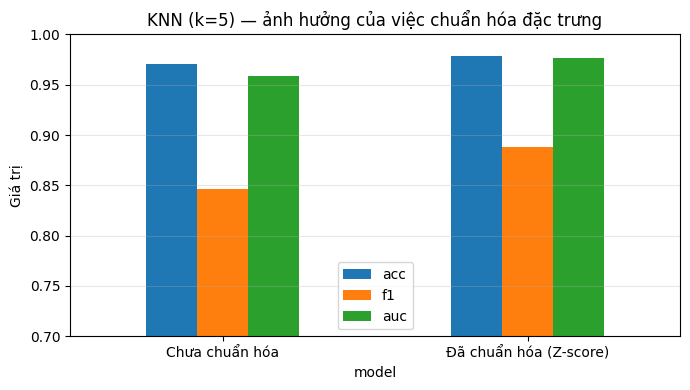

In [5]:
# KNN quyết định bằng KHOẢNG CÁCH, mà khoảng cách cộng dồn hiệu trên mọi
# chiều. Một đặc trưng có đơn vị lớn sẽ áp đảo các đặc trưng đơn vị nhỏ.
# Vì vậy sách vở thường nói "KNN bắt buộc phải chuẩn hóa". Ta ĐO THỬ thay vì
# tin ngay — kết quả trên ba bộ dữ liệu khác nhau không giống nhau.
rows = []
for tag, A, B in [("Chưa chuẩn hóa", X_tr_raw, X_te_raw),
                  ("Đã chuẩn hóa (Z-score)", X_tr, X_te)]:
    yp, ys, _ = fit_knn(A, y_tr, B, n_neighbors=5)
    rows.append(evaluate(y_te, yp, ys, tag))

scale_df = pd.DataFrame(rows).set_index("model").round(4)
print("KNN k=5 — ảnh hưởng của việc chuẩn hóa đặc trưng")
print(scale_df[["acc", "prec", "rec", "f1", "auc"]])
print(f"\nChênh lệch F1: {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(SCALE_COMMENT)

ax = scale_df[["acc", "f1", "auc"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_title("KNN (k=5) — ảnh hưởng của việc chuẩn hóa đặc trưng")
ax.set_ylabel("Giá trị")
ax.set_ylim(SCALE_YLIM)
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Chọn Số Láng Giềng k

       acc    prec     rec      f1     auc
k                                         
1   0.9899  0.9751  0.9288  0.9514  0.9630
3   0.9846  0.9685  0.8847  0.9247  0.9750
5   0.9781  0.9757  0.8153  0.8883  0.9764
7   0.9731  0.9642  0.7763  0.8601  0.9777
9   0.9698  0.9710  0.7390  0.8393  0.9796
11  0.9642  0.9757  0.6814  0.8024  0.9782
15  0.9599  0.9742  0.6407  0.7730  0.9796
21  0.9550  0.9671  0.5983  0.7393  0.9811
31  0.9505  0.9566  0.5610  0.7073  0.9800

→ k tốt nhất theo F1: k = 1  (F1 = 0.9514)
→ F1 tại k = 31: 0.7073

⚠ CẢNH BÁO: F1 giảm ĐƠN ĐIỆU từ k = 1 tới k = 31, không có đỉnh ở giữa.
Đây là dấu hiệu kinh điển của RÒ RỈ THỜI GIAN, không phải dấu hiệu mô hình
tốt. BATADAL lấy mẫu mỗi giờ nên trạng thái tại giờ t và giờ t−1 gần như
trùng nhau. train_test_split ngẫu nhiên đã đẩy mẫu giờ t vào tập test và
mẫu giờ t−1 vào tập train, nên k = 1 chỉ việc sao chép nhãn của chính nó
dịch đi một giờ. Phần A8 sẽ chứng minh con số này là ảo.


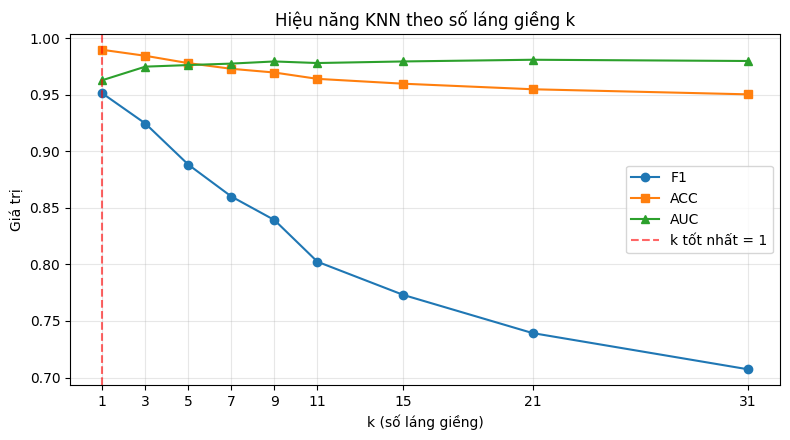

In [6]:
# k nhỏ  → biên quyết định gấp khúc, bám sát từng mẫu  → dễ overfit, nhạy nhiễu
#          (k = 1 nghĩa là mô hình chỉ sao chép nhãn của mẫu gần nhất)
# k lớn  → biên quyết định mượt, lấy ý kiến đa số rộng → dễ underfit, và lớp
#          thiểu số (tấn công) dễ bị lớp đa số lấn át trong phiếu bầu
rows = []
for k in K_GRID:
    yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k)
    rows.append(evaluate(y_te, yp, ys, k))

k_df = pd.DataFrame(rows).set_index("model").round(4)
k_df.index.name = "k"
print(k_df[["acc", "prec", "rec", "f1", "auc"]])

k_best = int(k_df["f1"].idxmax())
print(f"\n→ k tốt nhất theo F1: k = {k_best}  (F1 = {k_df.loc[k_best, 'f1']:.4f})")
print(f"→ F1 tại k = {K_GRID[-1]}: {k_df['f1'].iloc[-1]:.4f}")
print(KSWEEP_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, mk in [("f1", "o"), ("acc", "s"), ("auc", "^")]:
    ax.plot(k_df.index, k_df[col], marker=mk, label=col.upper())
ax.axvline(k_best, color="red", ls="--", alpha=.6, label=f"k tốt nhất = {k_best}")
ax.set_xlabel("k (số láng giềng)")
ax.set_ylabel("Giá trị")
ax.set_title("Hiệu năng KNN theo số láng giềng k")
ax.set_xticks(K_GRID)
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. So Sánh Metric Khoảng Cách & Trọng Số Phiếu

KNN k=1 — so sánh 3 metric × 2 kiểu trọng số
                       acc    prec     rec      f1     auc
model                                                     
manhattan|uniform   0.9901  0.9785  0.9271  0.9521  0.9623
manhattan|distance  0.9901  0.9785  0.9271  0.9521  0.9623
euclidean|uniform   0.9899  0.9751  0.9288  0.9514  0.9630
euclidean|distance  0.9899  0.9751  0.9288  0.9514  0.9630
chebyshev|uniform   0.9870  0.9625  0.9136  0.9374  0.9547
chebyshev|distance  0.9870  0.9625  0.9136  0.9374  0.9547

→ Cấu hình tốt nhất: metric=manhattan, weights=uniform  (F1 = 0.9521)

Nhận xét: Manhattan nhích hơn Euclidean một chút. Với k = 1, hai kiểu
trọng số uniform và distance cho kết quả giống nhau vì chỉ có một phiếu duy
nhất để bầu.


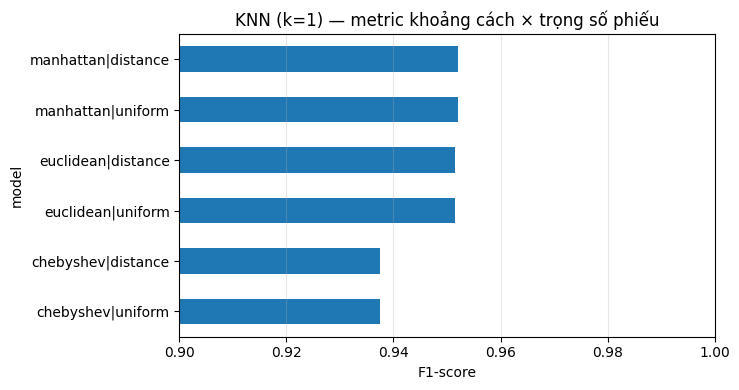

In [7]:
# euclidean (L2) : căn bậc hai tổng bình phương hiệu
# manhattan (L1) : tổng trị tuyệt đối hiệu — bền hơn với ngoại lai và theo
#                  thực nghiệm thường tốt hơn L2 khi số chiều cao
# chebyshev (L∞) : chỉ lấy hiệu lớn nhất trên một chiều, bỏ qua các chiều khác
#
# weights='uniform'  : mọi láng giềng một phiếu bằng nhau
# weights='distance' : láng giềng càng gần phiếu càng nặng, theo tỷ lệ 1/d
rows = []
for met in METRICS:
    for w in WEIGHTS:
        yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k_best,
                            metric=met, weights=w)
        rows.append(evaluate(y_te, yp, ys, f"{met}|{w}"))

combo_df = pd.DataFrame(rows).set_index("model").round(4)
print(f"KNN k={k_best} — so sánh {len(METRICS)} metric × {len(WEIGHTS)} kiểu trọng số")
print(combo_df[["acc", "prec", "rec", "f1", "auc"]].sort_values("f1", ascending=False))

combo_best = combo_df["f1"].idxmax()
best_metric, best_weights = combo_best.split("|")
print(f"\n→ Cấu hình tốt nhất: metric={best_metric}, weights={best_weights}"
      f"  (F1 = {combo_df.loc[combo_best, 'f1']:.4f})")
print(COMBO_COMMENT)

ax = combo_df["f1"].sort_values().plot.barh(figsize=(7.5, 4))
ax.set_xlabel("F1-score")
ax.set_title(f"KNN (k={k_best}) — metric khoảng cách × trọng số phiếu")
ax.set_xlim(COMBO_XLIM)
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A5. Số Chiều & Lời Nguyền Số Chiều (PCA)

evr = tỷ lệ phương sai được giữ lại sau khi giảm chiều
                  f1     auc     evr
n_components                        
2             0.4270  0.6736  0.3437
5             0.9179  0.9384  0.6257
10            0.9081  0.9364  0.8648
20            0.9469  0.9595  0.9980
37            0.9514  0.9630  1.0000

Nhận xét: giảm xuống 2 chiều làm F1 sụp đổ dù vẫn giữ khoảng 34% phương
sai, nhưng 20 chiều (99,8% phương sai) đã gần bằng dùng đủ số chiều. Nghĩa
là dấu hiệu tấn công nằm ở những thành phần phương sai nhỏ — chính là các
lệch nhẹ so với vận hành bình thường, chứ không nằm ở các thành phần dao
động mạnh nhất (nhịp bơm, chu kỳ ngày đêm).


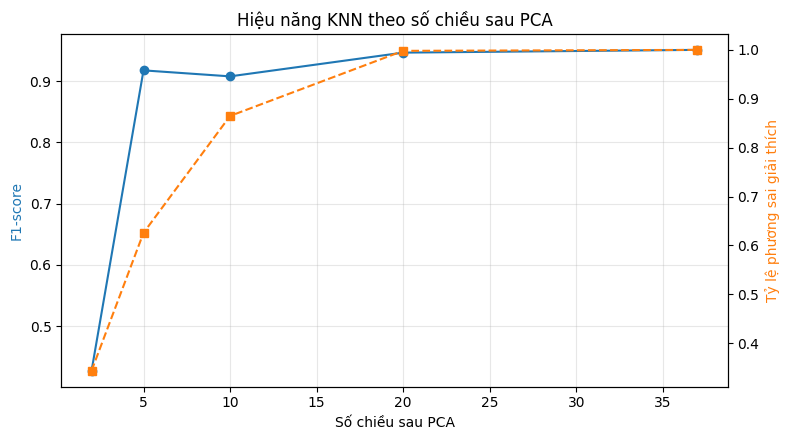

In [8]:
# Lời nguyền số chiều: khi số chiều tăng, khoảng cách từ một điểm tới mẫu gần
# nhất và tới mẫu xa nhất co lại gần bằng nhau → khái niệm "láng giềng" mất
# dần ý nghĩa, đồng thời chi phí tính khoảng cách tăng lên.
# PCA chiếu dữ liệu sang không gian ít chiều hơn mà vẫn giữ phần lớn phương sai.
rows = []
for nc in PCA_GRID:
    if nc >= X_tr.shape[1]:
        continue
    pca = PCA(n_components=nc, random_state=SEED).fit(X_tr)
    yp, ys, _ = fit_knn(pca.transform(X_tr), y_tr, pca.transform(X_te),
                        n_neighbors=k_best)
    r = evaluate(y_te, yp, ys, nc)
    r["evr"] = pca.explained_variance_ratio_.sum()
    rows.append(r)

# Mốc so sánh: dùng toàn bộ số chiều
yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k_best)
r = evaluate(y_te, yp, ys, X_tr.shape[1])
r["evr"] = 1.0
rows.append(r)

pca_df = pd.DataFrame(rows).set_index("model").round(4)
pca_df.index.name = "n_components"
print("evr = tỷ lệ phương sai được giữ lại sau khi giảm chiều")
print(pca_df[["f1", "auc", "evr"]])
print(PCA_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(pca_df.index, pca_df["f1"], marker="o", color="tab:blue", label="F1")
ax1.set_xlabel("Số chiều sau PCA")
ax1.set_ylabel("F1-score", color="tab:blue")
ax1.grid(alpha=.3)
ax2 = ax1.twinx()
ax2.plot(pca_df.index, pca_df["evr"], marker="s", ls="--", color="tab:orange")
ax2.set_ylabel("Tỷ lệ phương sai giải thích", color="tab:orange")
ax1.set_title("Hiệu năng KNN theo số chiều sau PCA")
plt.tight_layout()
plt.show()


### A6. Độ Trễ Suy Luận – Điểm Yếu Cốt Tử Của KNN

         ms_per_sample  samples_per_sec  mem_train_MB
n_train                                              
1000             0.053        18946.499         0.282
5000             0.072        13896.909         1.411
10000            0.075        13333.244         2.823
12903            0.085        11831.064         3.642

⚠ Con số tuyệt đối phụ thuộc cấu hình máy. Điều cần quan sát là XU HƯỚNG:
  tập train càng lớn thì mỗi dự đoán càng chậm, và toàn bộ tập train
  phải nằm trong bộ nhớ khi triển khai.

Nhận xét: hệ SCADA lấy mẫu mỗi giây hoặc mỗi phút nên độ trễ này hoàn
toàn đáp ứng được — khác với bài toán IDS đường trục. Hạn chế thật của KNN
trong ICS là phải lưu toàn bộ lịch sử vận hành trên thiết bị biên, và dữ
liệu đó lớn dần theo thời gian.


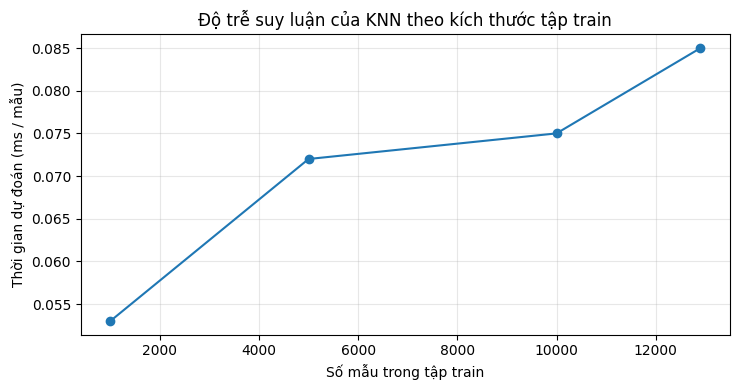

In [9]:
# KNN là "lazy learner": fit() gần như tức thì vì chỉ lưu dữ liệu, nhưng mỗi
# lần predict() phải đi tìm láng giềng trong TOÀN BỘ tập train. Chi phí suy
# luận vì thế tăng theo kích thước tập train — ngược hẳn với cây quyết định
# hay hồi quy logistic, nơi chi phí dự đoán là hằng số.
N_PROBE = 2000     # số mẫu dùng để đo thời gian
rows = []
for n in [1000, 5000, 10000, X_tr.shape[0]]:
    if n > X_tr.shape[0]:
        continue
    kn = KNeighborsClassifier(n_neighbors=k_best).fit(X_tr[:n], y_tr[:n])
    t0 = time.perf_counter()
    kn.predict(X_te[:N_PROBE])
    dt = time.perf_counter() - t0
    rows.append({"n_train": n,
                 "ms_per_sample": dt / N_PROBE * 1000,
                 "samples_per_sec": N_PROBE / dt,
                 "mem_train_MB": X_tr[:n].nbytes / 1024 / 1024})

lat_df = pd.DataFrame(rows).set_index("n_train").round(3)
print(lat_df)
print("\n⚠ Con số tuyệt đối phụ thuộc cấu hình máy. Điều cần quan sát là XU HƯỚNG:")
print("  tập train càng lớn thì mỗi dự đoán càng chậm, và toàn bộ tập train")
print("  phải nằm trong bộ nhớ khi triển khai.")
print(LATENCY_COMMENT)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(lat_df.index, lat_df["ms_per_sample"], marker="o")
ax.set_xlabel("Số mẫu trong tập train")
ax.set_ylabel("Thời gian dự đoán (ms / mẫu)")
ax.set_title("Độ trễ suy luận của KNN theo kích thước tập train")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Mô Hình Cuối – Confusion Matrix & Đường Cong ROC

                                  acc    prec     rec      f1  f1_macro  \
model                                                                     
KNN (k=1, manhattan, uniform)  0.9901  0.9785  0.9271  0.9521    0.9733   
Random Forest (200 cây)        0.9919  0.9964  0.9271  0.9605    0.9780   

                                  auc  
model                                  
KNN (k=1, manhattan, uniform)  0.9623  
Random Forest (200 cây)        0.9978  

Confusion matrix KNN:  TN=4928  FP=12  FN=43  TP=547
  FP = 12 cảnh báo giả | FN = 43 lần bỏ sót tấn công

              precision    recall  f1-score   support

 Bình thường     0.9913    0.9976    0.9945      4940
    Tấn công     0.9785    0.9271    0.9521       590

    accuracy                         0.9901      5530
   macro avg     0.9849    0.9623    0.9733      5530
weighted avg     0.9900    0.9901    0.9899      5530


Nhận xét: con số trông rất đẹp — chỉ 12 cảnh báo giả và 43 lần bỏ sót.
ĐỪNG TIN NGAY. Hãy chạy tiếp phầ

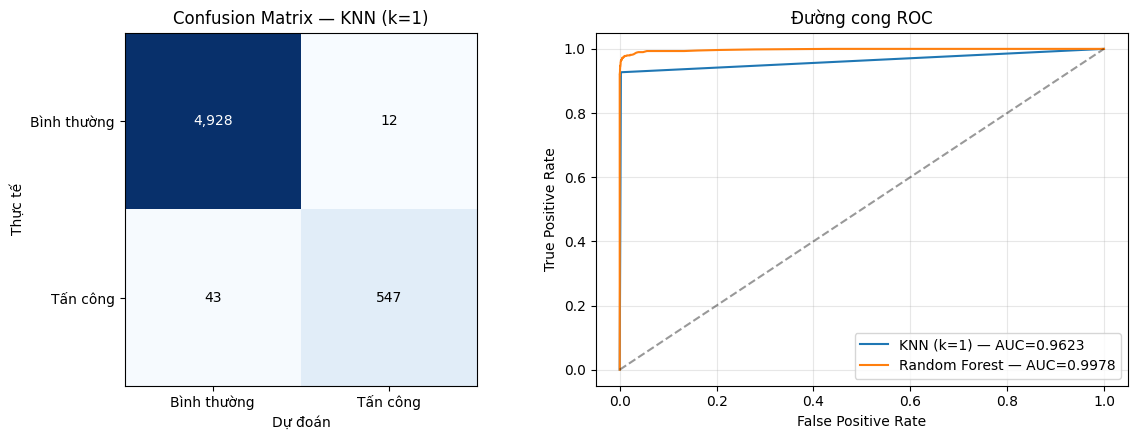

In [10]:
# Mô hình cuối dùng k, metric và weights tốt nhất đã tìm được ở A3 và A4.
# Random Forest 200 cây được huấn luyện trên cùng tập train để làm mốc so sánh.
y_pred, y_score, knn_final = fit_knn(
    X_tr, y_tr, X_te,
    n_neighbors=k_best, metric=best_metric, weights=best_weights)
knn_res = evaluate(y_te, y_pred, y_score,
                   f"KNN (k={k_best}, {best_metric}, {best_weights})")

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_score = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([knn_res, rf_res]).set_index("model").round(4)
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix KNN:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], TARGET_NAMES)
axes[0].set_yticks([0, 1], TARGET_NAMES)
axes[0].set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")
axes[0].set_title(f"Confusion Matrix — KNN (k={k_best})")

for nm, sc in [(f"KNN (k={k_best})", y_score), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Đánh Giá Trên Tập Held-Out (test_dataset_2)

                                      acc    prec     rec      f1  f1_macro  \
model                                                                         
KNN (k=1, manhattan, uniform)      0.9901  0.9785  0.9271  0.9521    0.9733   
KNN — Test 2 (held-out)            0.8624  0.7295  0.2353  0.3558    0.6394   
Random Forest (200 cây)            0.9919  0.9964  0.9271  0.9605    0.9780   
Random Forest — Test 2 (held-out)  0.8856  0.9760  0.2991  0.4579    0.6970   

                                      auc  
model                                      
KNN (k=1, manhattan, uniform)      0.9623  
KNN — Test 2 (held-out)            0.6092  
Random Forest (200 cây)            0.9978  
Random Forest — Test 2 (held-out)  0.8762  

Confusion matrix KNN trên Test 2:  TN=8311  FP=142  FN=1245  TP=383

→ F1 tụt từ 0.9521 (test ngẫu nhiên) xuống 0.3558 (held-out thật)
→ Recall chỉ còn 0.2353: bỏ sót 1,245/1,628 mẫu tấn công
→ AUC rơi từ 0.9623 xuống 0.6092, trong khi Random Forest giữ được 0

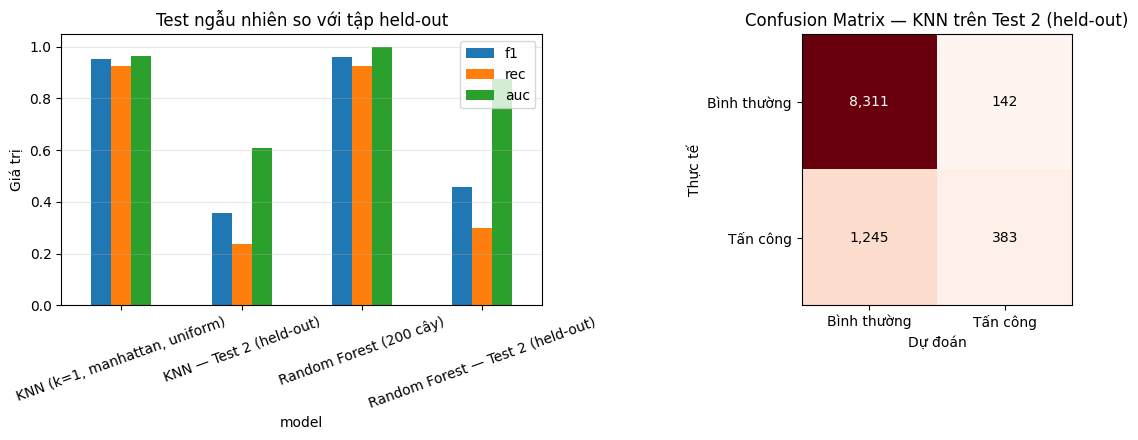

In [11]:
# Tập test ở A7 được tách NGẪU NHIÊN từ cùng chuỗi thời gian với tập train.
# BATADAL lấy mẫu mỗi giờ, nên hai mốc liền kề gần như trùng nhau — tách ngẫu
# nhiên khiến "láng giềng theo thời gian" của một mẫu test lại nằm trong tập
# train. Đó là RÒ RỈ THỜI GIAN (temporal leakage).
#
# test_dataset_2 thuộc một giai đoạn tấn công hoàn toàn khác, không liền kề
# thời gian với tập train → đây mới là phép thử phản ánh năng lực thật.
X_ho = scaler.transform(X_ho_raw.values)

yp_ho = knn_final.predict(X_ho)
ys_ho = knn_final.predict_proba(X_ho)[:, 1]
ho_res = evaluate(y_ho, yp_ho, ys_ho, "KNN — Test 2 (held-out)")

rf_ho_score = rf.predict_proba(X_ho)[:, 1]
rf_ho = evaluate(y_ho, rf.predict(X_ho), rf_ho_score,
                 "Random Forest — Test 2 (held-out)")

ho_df = pd.DataFrame([knn_res, ho_res, rf_res, rf_ho]).set_index("model").round(4)
print(ho_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])

cm_ho = confusion_matrix(y_ho, yp_ho)
tn2, fp2, fn2, tp2 = cm_ho.ravel()
print(f"\nConfusion matrix KNN trên Test 2:  TN={tn2}  FP={fp2}  FN={fn2}  TP={tp2}")
print(f"\n→ F1 tụt từ {knn_res['f1']:.4f} (test ngẫu nhiên) "
      f"xuống {ho_res['f1']:.4f} (held-out thật)")
print(f"→ Recall chỉ còn {ho_res['rec']:.4f}: bỏ sót {fn2:,}/{int(y_ho.sum()):,} "
      f"mẫu tấn công")
print(f"→ AUC rơi từ {knn_res['auc']:.4f} xuống {ho_res['auc']:.4f}, trong khi "
      f"Random Forest giữ được {rf_ho['auc']:.4f}")
print(HELDOUT_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ho_df[["f1", "rec", "auc"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Test ngẫu nhiên so với tập held-out")
axes[0].set_ylabel("Giá trị")
axes[0].grid(axis="y", alpha=.3)

axes[1].imshow(cm_ho, cmap="Reds")
for (i, j), v in np.ndenumerate(cm_ho):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm_ho.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — KNN trên Test 2 (held-out)")
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Chuẩn hóa Z-score có tác dụng rõ rệt với dữ liệu cảm biến ICS, vì các cảm biến có đơn vị hoàn toàn khác nhau.
2. `k = 1` cho F1 cao nhất và F1 **giảm đơn điệu** khi `k` tăng — dấu hiệu cảnh báo, không phải dấu hiệu tốt.
3. Trên tập test chia ngẫu nhiên, mô hình đạt F1 khoảng 0,95; trên tập held-out, F1 chỉ còn khoảng 0,36 và Recall khoảng 0,24.
4. Nguyên nhân là rò rỉ thời gian: `train_test_split` ngẫu nhiên là cách chia **sai** với dữ liệu chuỗi thời gian.
5. Random Forest cũng suy giảm nhưng giữ được AUC cao hơn nhiều, vì học quy luật chung thay vì ghi nhớ từng mốc thời gian.

**Câu hỏi thảo luận**

1. BATADAL lấy mẫu mỗi giờ. Hãy giải thích cụ thể vì sao việc chia ngẫu nhiên khiến "láng giềng gần nhất" của một mẫu test gần như chắc chắn là mẫu liền kề về thời gian của nó trong tập train.
2. Trong hai con số F1 ở phần A8, con số nào phản ánh năng lực thật của mô hình khi triển khai, và vì sao?
3. Vì sao AUC của KNN rơi mạnh hơn Random Forest trên tập held-out? Gợi ý: với `k = 1`, `predict_proba` chỉ nhận được những giá trị nào?
4. Nếu phải sửa thiết kế thực nghiệm cho đúng, bạn sẽ chia train/test theo cách nào thay cho `train_test_split` ngẫu nhiên? Hãy nêu cụ thể cách chia và lý do.
5. Vì sao dữ liệu cảm biến ICS phụ thuộc mạnh vào việc chuẩn hóa, trong khi hai bộ dữ liệu của CV4.1 và CV4.2 thì không?
6. Giảm xuống 2 chiều PCA làm F1 sụp đổ dù giữ được khoảng 34% phương sai, nhưng 20 chiều (99,8% phương sai) đã gần tương đương dùng đủ số chiều. Điều này nói gì về cách phân bố thông tin tấn công trong không gian cảm biến?
7. Với hệ SCADA, một cảnh báo giả khiến kỹ sư phải dừng kiểm tra quy trình. Dựa trên confusion matrix trên tập held-out, hãy đánh giá mô hình này có dùng được trong vận hành thật hay không.
